In [1]:
import pandas as pd

# Load the dataset
data = pd.read_excel(r'C:\Users\shahu\OPEN CLASSROOMS\PROJET 3\outputs\data_modelisation.xlsx')
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,hasEnergyStarScore,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,NaN,0,NaN,0,60.000000,7456910,250,1,98,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,61.000000,8664479,296,1,29,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,NaN,0,NaN,0,56.000000,6946801,286,1,99,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,NaN,0,75.000000,14656503,505,1,45,0.850914,0.366295,EN,0
4,Nonresidential COS,98101,2,37198,police station,88830,NaN,0,NaN,0,60.909091,12581712,302,0,26,0.850914,0.585885,EN,0


# MODELISATION WITH ENERGYSTARScore

In [2]:
# Step 1: Filter rows where hasEnergyStarScore == 1
data = data[data["hasEnergyStarScore"] == 1].copy()

# Step 2: Drop the column
data = data.drop(columns=["hasEnergyStarScore"])

print(f"✅ Kept only rows with hasEnergyStarScore == 1.")
print(f"Remaining rows: {len(data)}")
print(f"Remaining columns: {len(data.columns)}")


✅ Kept only rows with hasEnergyStarScore == 1.
Remaining rows: 1058
Remaining columns: 18


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
import numpy as np



# Identify categorical and numeric columns
cat_cols = data.select_dtypes(include=["object", "category"]).columns
num_cols = data.select_dtypes(exclude=["object", "category"]).columns.drop(["SiteEnergyUseWN(kBtu)", "TotalGHGEmissions"])

# Convert all categorical columns to string
for col in cat_cols:
    data[col] = data[col].astype(str)
print("✅ Converted categorical columns to string type for OneHotEncoder compatibility.")

# Preprocessing:
# - One-hot encode categorical
# - Scale numeric (needed for linear models, harmless for trees)
preprocessor = ColumnTransformer([
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ("num", StandardScaler(), num_cols)
])



✅ Converted categorical columns to string type for OneHotEncoder compatibility.


In [4]:
print(cat_cols)

Index(['BuildingType', 'ZipCode', 'LargestPropertyUseType',
       'SecondLargestPropertyUseType', 'ThirdLargestPropertyUseType',
       'EnergyMix'],
      dtype='object')


In [5]:
print(num_cols)

Index(['NumberofFloors', 'PropertyGFAParking', 'LargestPropertyUseTypeGFA',
       'SecondLargestPropertyUseTypeGFA', 'ThirdLargestPropertyUseTypeGFA',
       'ENERGYSTARScore', 'Age', 'Ratio_LargestPropertyShare',
       'Ratio_ElectricityShare', 'isMixedProperty'],
      dtype='object')


In [6]:
data.head()

,BuildingType,ZipCode,NumberofFloors,PropertyGFAParking,LargestPropertyUseType,LargestPropertyUseTypeGFA,SecondLargestPropertyUseType,SecondLargestPropertyUseTypeGFA,ThirdLargestPropertyUseType,ThirdLargestPropertyUseTypeGFA,ENERGYSTARScore,SiteEnergyUseWN(kBtu),TotalGHGEmissions,Age,Ratio_LargestPropertyShare,Ratio_ElectricityShare,EnergyMix,isMixedProperty
0,NonResidential,98101,12,0,hotel,88434,nan,0,nan,0,60.0,7456910,250,98,1.000000,0.529177,SEN,0
1,NonResidential,98101,11,15064,hotel,83880,parking,15064,restaurant,4622,61.0,8664479,296,29,0.947775,0.374270,EN,1
2,NonResidential,98101,10,0,hotel,61320,nan,0,nan,0,56.0,6946801,286,99,1.000000,0.398590,SEN,0
3,NonResidential,98121,18,62000,hotel,123445,parking,68009,nan,0,75.0,14656503,505,45,0.850914,0.366295,EN,0
5,NonResidential,98101,11,0,hotel,81352,nan,0,nan,0,27.0,6062768,176,99,0.980050,0.463685,EN,0


In [7]:
pip install catboost

Note: you may need to restart the kernel to use updated packages.


In [8]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from catboost import CatBoostRegressor

models = {
    "LinearRegression": LinearRegression(),
    "Ridge": Ridge(alpha=1.0),
    "Lasso": Lasso(alpha=0.001),
    "RandomForest": RandomForestRegressor(n_estimators=200, random_state=42),
    "GradientBoosting": GradientBoostingRegressor(random_state=42),
    "CatBoost": CatBoostRegressor(verbose=0, random_state=42)
}


In [9]:
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_percentage_error
from sklearn.model_selection import train_test_split
import pandas as pd

# Split data
features = [c for c in data.columns if c not in ["SiteEnergyUseWN(kBtu)", "TotalGHGEmissions"]]
X = data[features]
y_energy = data["SiteEnergyUseWN(kBtu)"]
y_ghg = data["TotalGHGEmissions"]

X_train, X_test, y_train_e, y_test_e = train_test_split(X, y_energy, test_size=0.2, random_state=42)
_, _, y_train_g, y_test_g = train_test_split(X, y_ghg, test_size=0.2, random_state=42)

# Results storage
results = []

for name, model in models.items():
    pipe = Pipeline(steps=[("preprocessor", preprocessor), ("model", model)])
    
    # Train & predict Energy
    pipe.fit(X_train, y_train_e)
    y_pred_e = pipe.predict(X_test)
    r2_e = r2_score(y_test_e, y_pred_e)
    rmse_e = np.sqrt(mean_squared_error(y_test_e, y_pred_e))
    mape_e = mean_absolute_percentage_error(y_test_e, y_pred_e)
    
    # Train & predict GHG
    pipe.fit(X_train, y_train_g)
    y_pred_g = pipe.predict(X_test)
    r2_g = r2_score(y_test_g, y_pred_g)
    rmse_g = np.sqrt(mean_squared_error(y_test_g, y_pred_g))
    mape_g = mean_absolute_percentage_error(y_test_g, y_pred_g)
    
    results.append({
        "Model": name,
        "R2_Energy": r2_e,
        "RMSE_Energy": rmse_e,
        "MAPE_Energy": mape_e,
        "R2_GHG": r2_g,
        "RMSE_GHG": rmse_g,
        "MAPE_GHG": mape_g
    })

# Display comparison
results_df = pd.DataFrame(results).sort_values(by="R2_Energy", ascending=False)
display(results_df)


c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.354e+15, tolerance: 5.961e+12
  model = cd_fast.sparse_enet_coordinate_descent(
c:\Users\shahu\anaconda3\envs\env\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:656: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 1.412e+05, tolerance: 3.027e+03
  model = cd_fast.sparse_enet_coordinate_descent(


,Model,R2_Energy,RMSE_Energy,MAPE_Energy,R2_GHG,RMSE_GHG,MAPE_GHG
5,CatBoost,0.895099,2.233295e+06,0.315254,0.824474,62.016893,0.489791
3,RandomForest,0.877802,2.410394e+06,0.427338,0.735567,76.119772,0.611739
4,GradientBoosting,0.865186,2.531764e+06,0.389876,0.738163,75.745192,0.733881
1,Ridge,0.799412,3.088217e+06,0.854306,0.610420,92.392768,2.460794
0,LinearRegression,0.799210,3.089776e+06,0.900406,0.612137,92.188931,2.473806
2,Lasso,0.796037,3.114090e+06,0.901541,0.612080,92.195722,2.473934


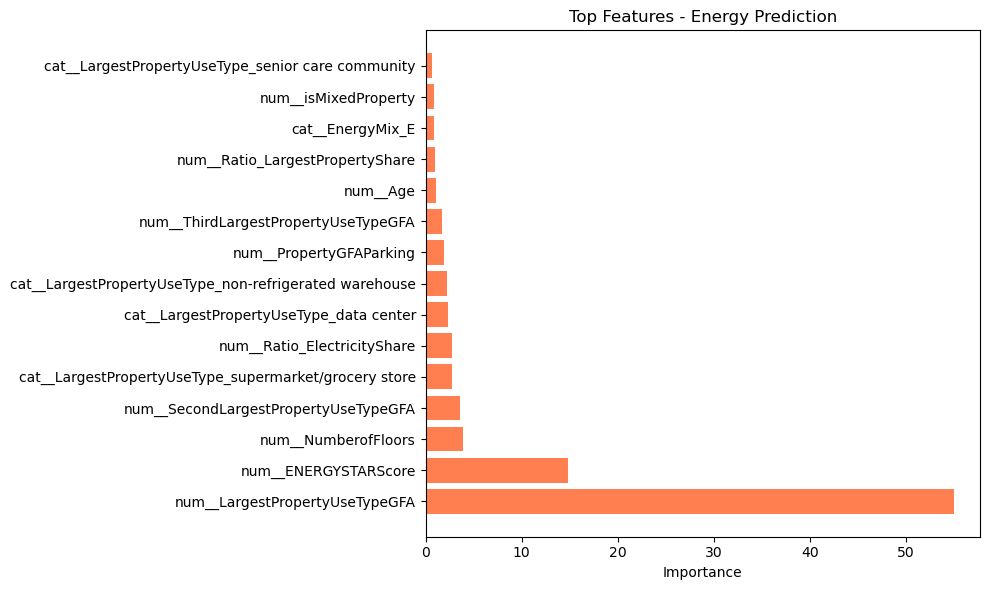

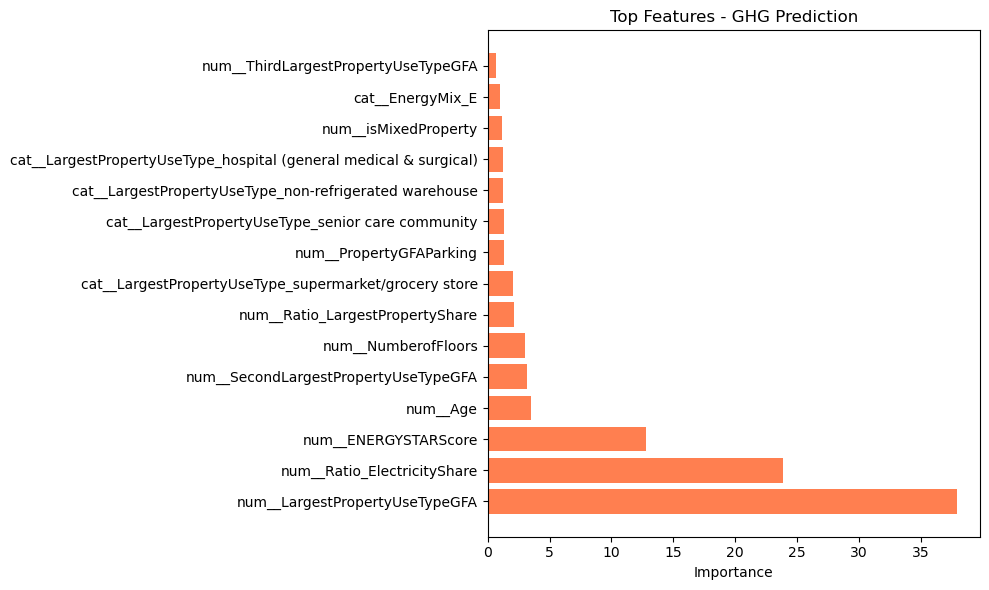

In [10]:
# Feature importance for BOTH Energy and GHG models
import matplotlib.pyplot as plt
for target_name, y_data in [("Energy", y_train_e), ("GHG", y_train_g)]:
    pipe = Pipeline(steps=[("preprocessor", preprocessor), 
                           ("model", CatBoostRegressor(verbose=0))])
    pipe.fit(X_train, y_data)
    
    model = pipe.named_steps["model"]
    feature_names = pipe.named_steps["preprocessor"].get_feature_names_out()
    importance = model.get_feature_importance()
    
    importance_df = pd.DataFrame({
        "Feature": feature_names,
        "Importance": importance
    }).sort_values(by="Importance", ascending=False)
    
    # Plot
    plt.figure(figsize=(10, 6))
    plt.barh(importance_df.head(15)["Feature"], 
             importance_df.head(15)["Importance"], color="coral")
    plt.xlabel("Importance")
    plt.title(f"Top Features - {target_name} Prediction")
    plt.tight_layout()
    plt.show()
